<a href="https://colab.research.google.com/github/rachnaa-s/ML-lab-Weather-prediction/blob/main/weather_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, mean_absolute_error, r2_score

# Option A: load directly from the web (works in Colab)
url = "https://raw.githubusercontent.com/vega/vega-datasets/main/data/seattle-weather.csv"
df = pd.read_csv(url, parse_dates=["date"])

# Option B: upload seattle-weather.csv to Colab (left folder icon) and use:
# df = pd.read_csv("seattle-weather.csv", parse_dates=["date"])

df.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   date           1461 non-null   datetime64[ns]
 1   precipitation  1461 non-null   float64       
 2   temp_max       1461 non-null   float64       
 3   temp_min       1461 non-null   float64       
 4   wind           1461 non-null   float64       
 5   weather        1461 non-null   object        
dtypes: datetime64[ns](1), float64(4), object(1)
memory usage: 68.6+ KB
None
                      date  precipitation     temp_max     temp_min  \
count                 1461    1461.000000  1461.000000  1461.000000   
mean   2013-12-31 00:00:00       3.029432    16.439083     8.234771   
min    2012-01-01 00:00:00       0.000000    -1.600000    -7.100000   
25%    2012-12-31 00:00:00       0.000000    10.600000     4.400000   
50%    2013-12-31 00:00:00       0.000000    15.600000

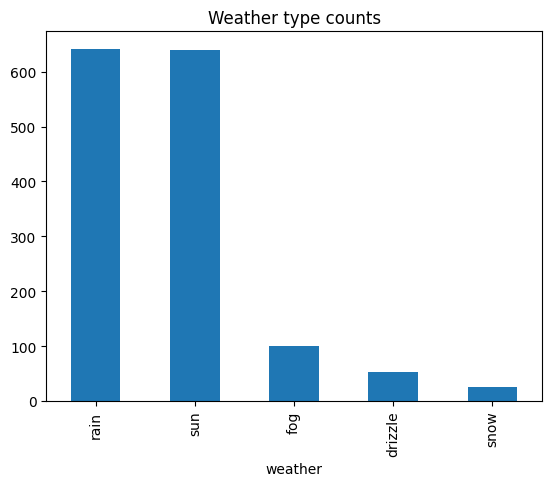

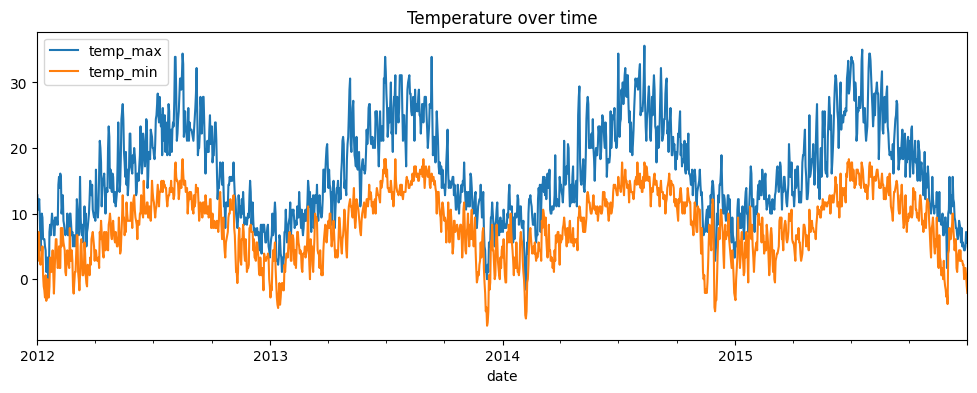

In [ ]:
print(df.info())
print(df.describe())
print(df['weather'].value_counts())

df['weather'].value_counts().plot(kind='bar', title='Weather type counts')
plt.show()

df.set_index('date')[['temp_max','temp_min']].plot(figsize=(12,4), title='Temperature over time')
plt.show()

Accuracy: 0.843
              precision    recall  f1-score   support

     drizzle       0.25      0.09      0.13        11
         fog       0.57      0.20      0.30        20
        rain       0.97      0.91      0.94       129
        snow       1.00      0.40      0.57         5
         sun       0.77      0.96      0.86       128

    accuracy                           0.84       293
   macro avg       0.71      0.51      0.56       293
weighted avg       0.83      0.84      0.82       293



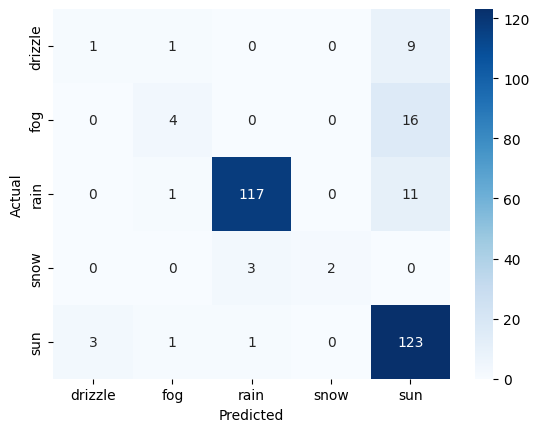

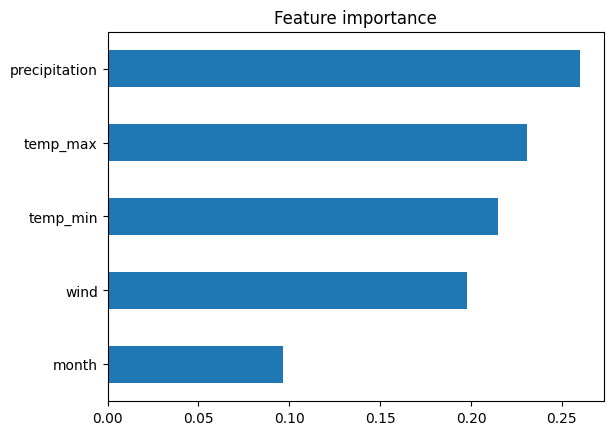

In [ ]:
data = df.copy()
data['month'] = data['date'].dt.month
data['dayofyear'] = data['date'].dt.dayofyear

features = ['precipitation','temp_max','temp_min','wind','month']
X = data[features]
y = data['weather']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

clf = RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced')
clf.fit(X_train, y_train)
pred = clf.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, zero_division=0))

sns.heatmap(confusion_matrix(y_test, pred, labels=clf.classes_), annot=True, fmt='d',
            xticklabels=clf.classes_, yticklabels=clf.classes_, cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

pd.Series(clf.feature_importances_, index=features).sort_values().plot(kind='barh', title='Feature importance')
plt.show()

MAE (deg C): 2.38
R2: 0.831


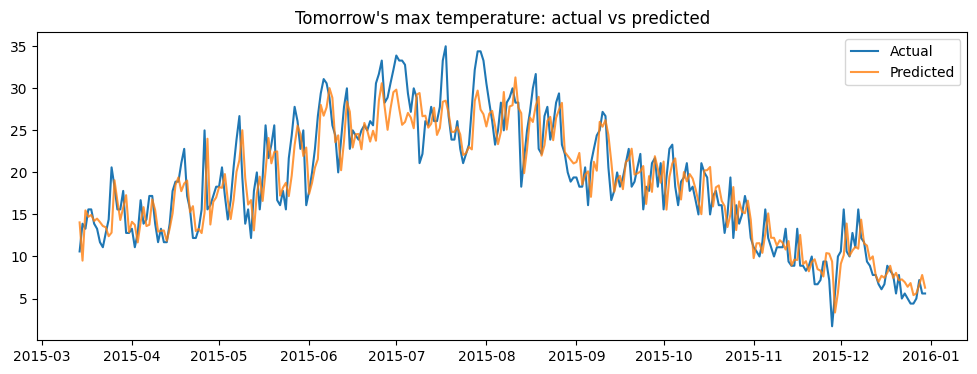

In [ ]:
ts = df.sort_values('date').reset_index(drop=True).copy()
ts['month'] = ts['date'].dt.month

for lag in [1, 2, 3]:
    for col in ['temp_max','temp_min','precipitation','wind']:
        ts[f'{col}_lag{lag}'] = ts[col].shift(lag - 1)   # lag1 = today

ts['target_temp_max_tomorrow'] = ts['temp_max'].shift(-1)
ts = ts.dropna().reset_index(drop=True)

feat_cols = [c for c in ts.columns if '_lag' in c] + ['month']
X = ts[feat_cols]
y = ts['target_temp_max_tomorrow']

split = int(len(ts) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

reg = RandomForestRegressor(n_estimators=300, random_state=42)
reg.fit(X_train, y_train)
p = reg.predict(X_test)

print("MAE (deg C):", round(mean_absolute_error(y_test, p), 2))
print("R2:", round(r2_score(y_test, p), 3))

plt.figure(figsize=(12,4))
plt.plot(ts['date'].iloc[split:], y_test.values, label='Actual')
plt.plot(ts['date'].iloc[split:], p, label='Predicted', alpha=0.8)
plt.legend(); plt.title("Tomorrow's max temperature: actual vs predicted"); plt.show()

In [ ]:
# Classify weather from custom inputs
sample = pd.DataFrame([{'precipitation': 8.0, 'temp_max': 12.0, 'temp_min': 6.0, 'wind': 5.0, 'month': 11}])
print("Predicted weather:", clf.predict(sample)[0])

# Predict tomorrow's max temp using the latest 3 days in the dataset
latest = ts[feat_cols].iloc[[-1]]
print("Predicted next-day max temp:", round(reg.predict(latest)[0], 1), "deg C")

Predicted weather: rain
Predicted next-day max temp: 6.3 deg C
